# 🧪 LAB: Clustering several real datasets

**Motivation**: This lab adopts three contrasting datasets to illustrate how clustering behaves under different real-world conditions—differences in scale, varying cluster separations, and high-dimensional gene expression data. You will put these concepts into practice by applying different clustering methods and evaluating how well they uncover structure in each dataset.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Laine Goldmacher, Max Magrill, and Ashley Qin"

## Part 1: Clustering arrests by U.S. state (25 points)

The dataset below contains statistics for the 50 U.S. states on four variables recorded in 1973:

- Murder: Arrests for murder (per 100,000 residents)
- Assault: Arrests for assault (per 100,000 residents)
- UrbanPop: Percentage of urban population
- Rape: Arrests for rape (per 100,000 residents)

1. Perform hierarchical clustering using complete linkage and Euclidean distance. Plot the resulting dendrogram.

2. Cut the dendrogram at a height that produces three clusters. Which states belong to each cluster?

3. Repeat the hierarchical clustering, again using complete linkage and Euclidean distance, after scaling all variables to have a standard deviation equal to one.

4. Compare the two clustering solutions. What effect does scaling the variables have on the resulting dendrogram and cluster memberships?
In your opinion, should the variables be scaled in this case before computing inter-observation dissimilarities? Provide a justification for your answer.

In [14]:
import pandas as pd 
dat_1 = pd.read_csv("Lab08-part1_data.csv")
states = dat_1.state.to_list()
X = dat_1.drop(columns="state")
X.head() # This is the dataset to use

,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


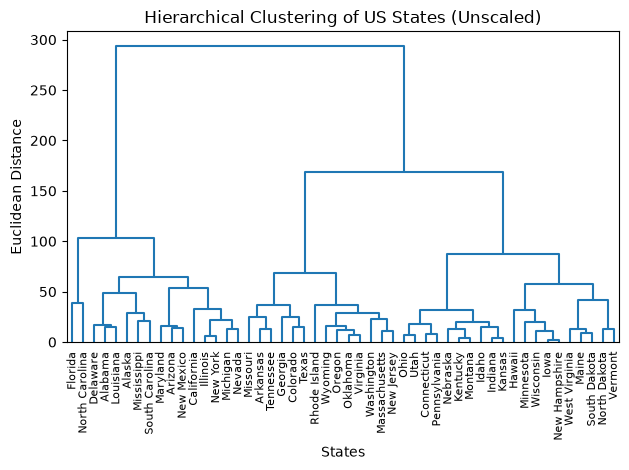

In [15]:
# 1 Hierarchical clustering
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X, method='complete', metric='euclidean') 
dendrogram(Z, color_threshold=0, labels=states)

plt.title("Hierarchical Clustering of US States (Unscaled)")
plt.xlabel("States")
plt.ylabel("Euclidean Distance")
plt.tight_layout()

plt.show()

In [16]:
# 2 Cutting Dendrogram
clusters = fcluster(Z, t=3, criterion='maxclust')

for i in range(1, 4):
    members = [states[j] for j in range(len(states)) if clusters[j] == i]
    print(f"Cluster {i} ({len(members)} states):")
    print(", ".join(members))
    print()

Cluster 1 (16 states):
Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states):
Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states):
Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin



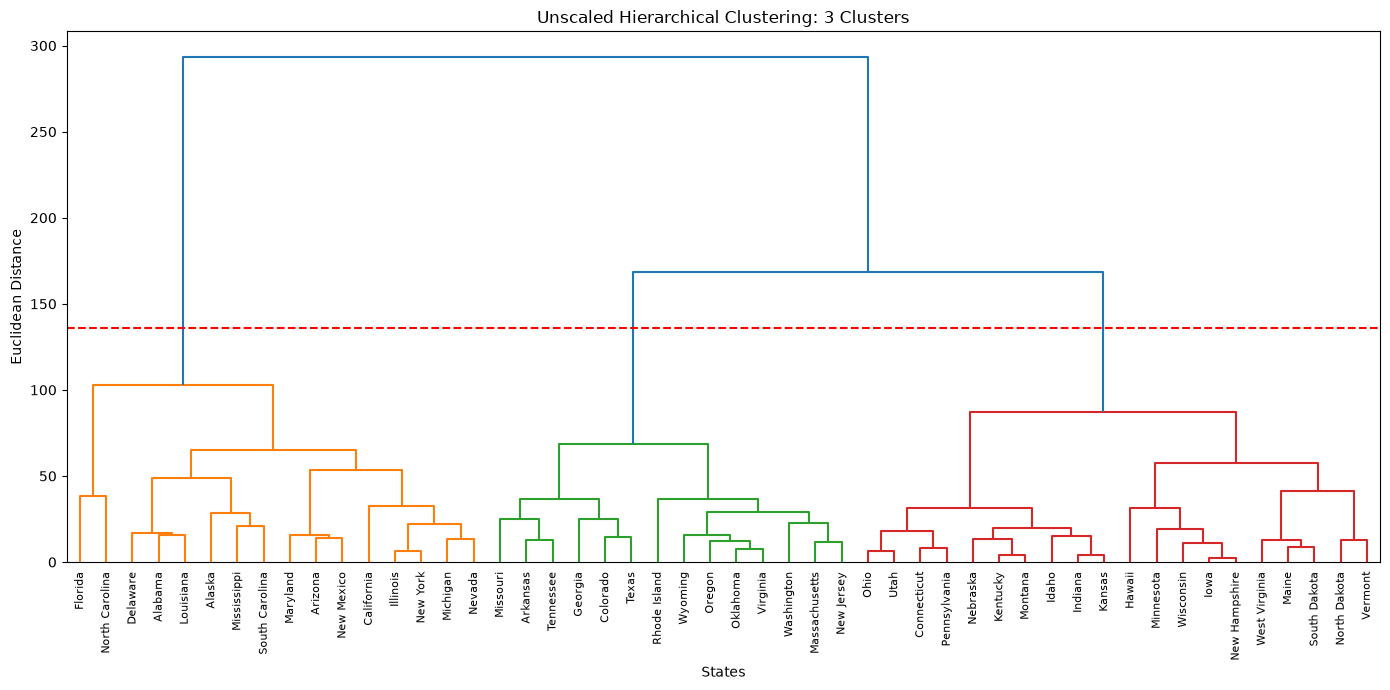

In [17]:
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(14, 7))
dendrogram(Z, labels=states, leaf_rotation=90, color_threshold=cut_height)
plt.axhline(y=cut_height, color='red', linestyle='--')
plt.title("Unscaled Hierarchical Clustering: 3 Clusters")
plt.xlabel("States")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

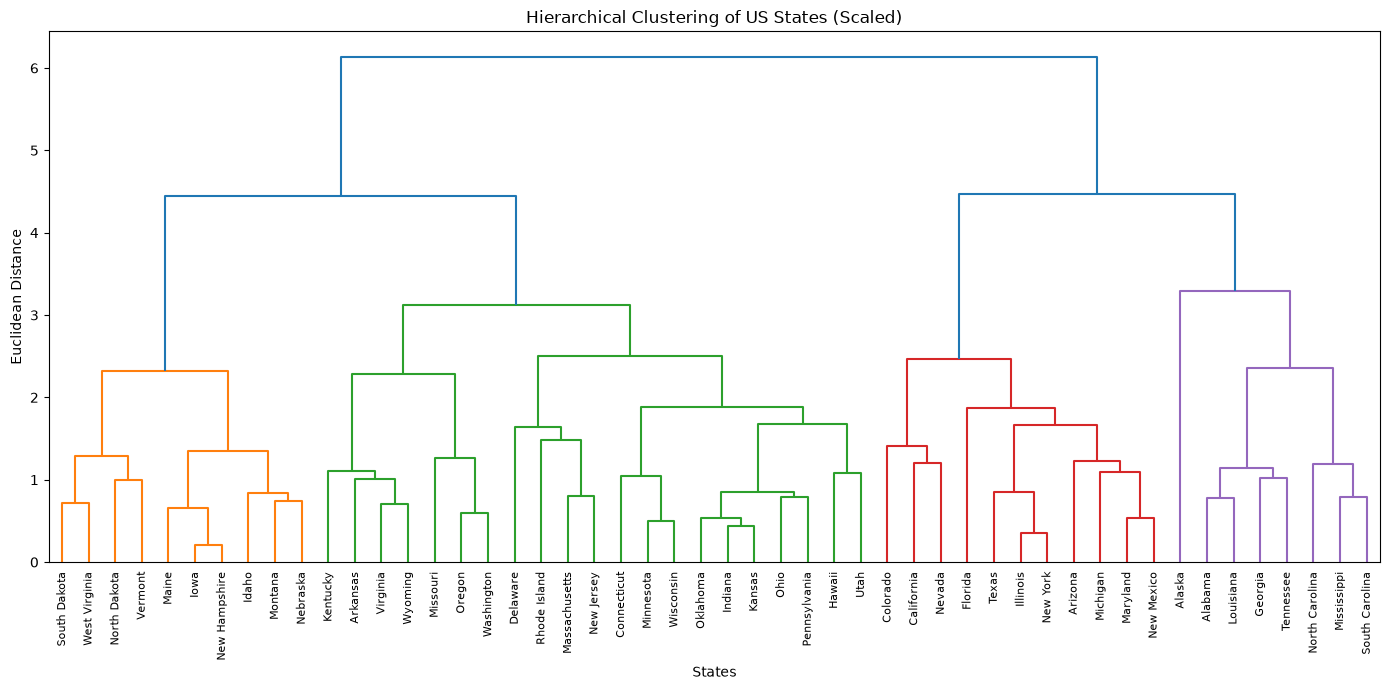

Cluster 1 (31 states):
Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming

Cluster 2 (11 states):
Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas

Cluster 3 (8 states):
Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee



In [18]:
# 3 Scale and Repeat
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Z_scaled = linkage(
    X_scaled,
    method='complete',
    metric='euclidean'
)

plt.figure(figsize=(14, 7))
dendrogram(Z_scaled, labels=states, leaf_rotation=90)
plt.title("Hierarchical Clustering of US States (Scaled)")
plt.xlabel("States")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

clusters_scaled = fcluster(Z_scaled, t=3, criterion='maxclust')

for i in range(1, 4):
    members = [states[j] for j in range(len(states)) if clusters_scaled[j] == i]
    print(f"Cluster {i} ({len(members)} states):")
    print(", ".join(members))
    print()

In [19]:
# 4 Comparing Solutions
comparison = pd.DataFrame({
    'State': states,
    'Unscaled Cluster': clusters,
    'Scaled Cluster': clusters_scaled
})

display(comparison)

,State,Unscaled Cluster,Scaled Cluster
0,Alabama,1,3
1,Alaska,1,3
2,Arizona,1,2
3,Arkansas,2,1
4,California,1,2
5,Colorado,2,2
6,Connecticut,3,1
7,Delaware,1,1
8,Florida,1,2
9,Georgia,2,3


In [20]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(clusters, clusters_scaled)
print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.3680405626883569


Scaling the variables changed both the dendrogram structure & which cluster each state belonged to. Without scaling, the three clusters contained 16, 14, and 20 states. With scaling, they contained 31, 11, and 8 states. The Adjusted Rand Index between the two solutions was 0.368, indicating relatively low agreement in cluster memberships.

Scaling allows each variable to have a standard deviation of one, so Murder, Assault, UrbanPop, and Rape contribute more equally to the distances. This changes how states are grouped. For example, Alabama and Arizona were in the same cluster before scaling but were placed in different clusters afterward.

I believe the variables should be scaled before clustering because they are measured on different scales, and we want all four characteristics to influence the results. Without scaling, the clusters mainly reflect differences in assault arrest rates rather than overall similarities across all four variables. Scaling produces a more balanced comparison of the states.

## Part 2: Clustering, genomic data, and cancer (35 points)

Unsupervised techniques are often used to analyze genomic data. In particular, PCA and hierarchical clustering are popular tools.
You will apply these techniques to the dataset below, which consists of gene expression measurements for 64 cancer cell lines across 6,830 genes.

1. Perform hierarchical clustering of the data using complete, single, and average linkage. Use Euclidean distance as the distance metric in all three cases.

2. Plot the dendrogram for each linkage method. Briefly describe the structure of these dendrograms and comment on the main differences produced by the three linkage criteria.

3. Using the known cancer type labels and examining each dendrogram, qualitatively describe how well the samples cluster into distinct cancer types. Do you see clear separation between some types? Which ones appear more mixed?

4. Focusing on complete linkage, plot the dendrogram again and cut it to obtain 4 clusters (e.g., highlight or color the branches). Briefly describe which cancer cell lines cluster together (for example, which cancer types tend to appear in the same cluster). Compute internal validation scores for this 4-cluster partition (e.g., Silhouette score, Calinski–Harabasz index, Davies–Bouldin index).

5. Fit a K-Means model with 4 clusters to the same data. Compare this 4-cluster K-Means solution with the 4-cluster hierarchical solution from step 4. How similar are the two partitions? Use at least one external validation metric (e.g., Adjusted Rand Index) to quantify their agreement.

6. Genomic data can be noisy and high-dimensional. To address this, apply PCA to the original data and reduce it to the first 5 principal components. Then perform hierarchical clustering with complete linkage and Euclidean distance on this reduced 5-dimensional representation. Cut the resulting dendrogram to obtain 4 clusters.

7. Compute the internal validation metrics for this PCA-based 4-cluster solution. Do these values indicate better or worse quality than those obtained using the original (non-reduced) data? In addition, compare the agreement between the PCA-based partition and the original partition using at least one external validation metric. Comment on whether dimensionality reduction improved, worsened, or did not change the clustering quality.

In [21]:
import pandas as pd
X = pd.read_csv("Lab08-part2_data.csv") # This is the dataset to use
# These are the labels for each observation
y = pd.read_csv("Lab08-part2_labels.csv").label.to_numpy()

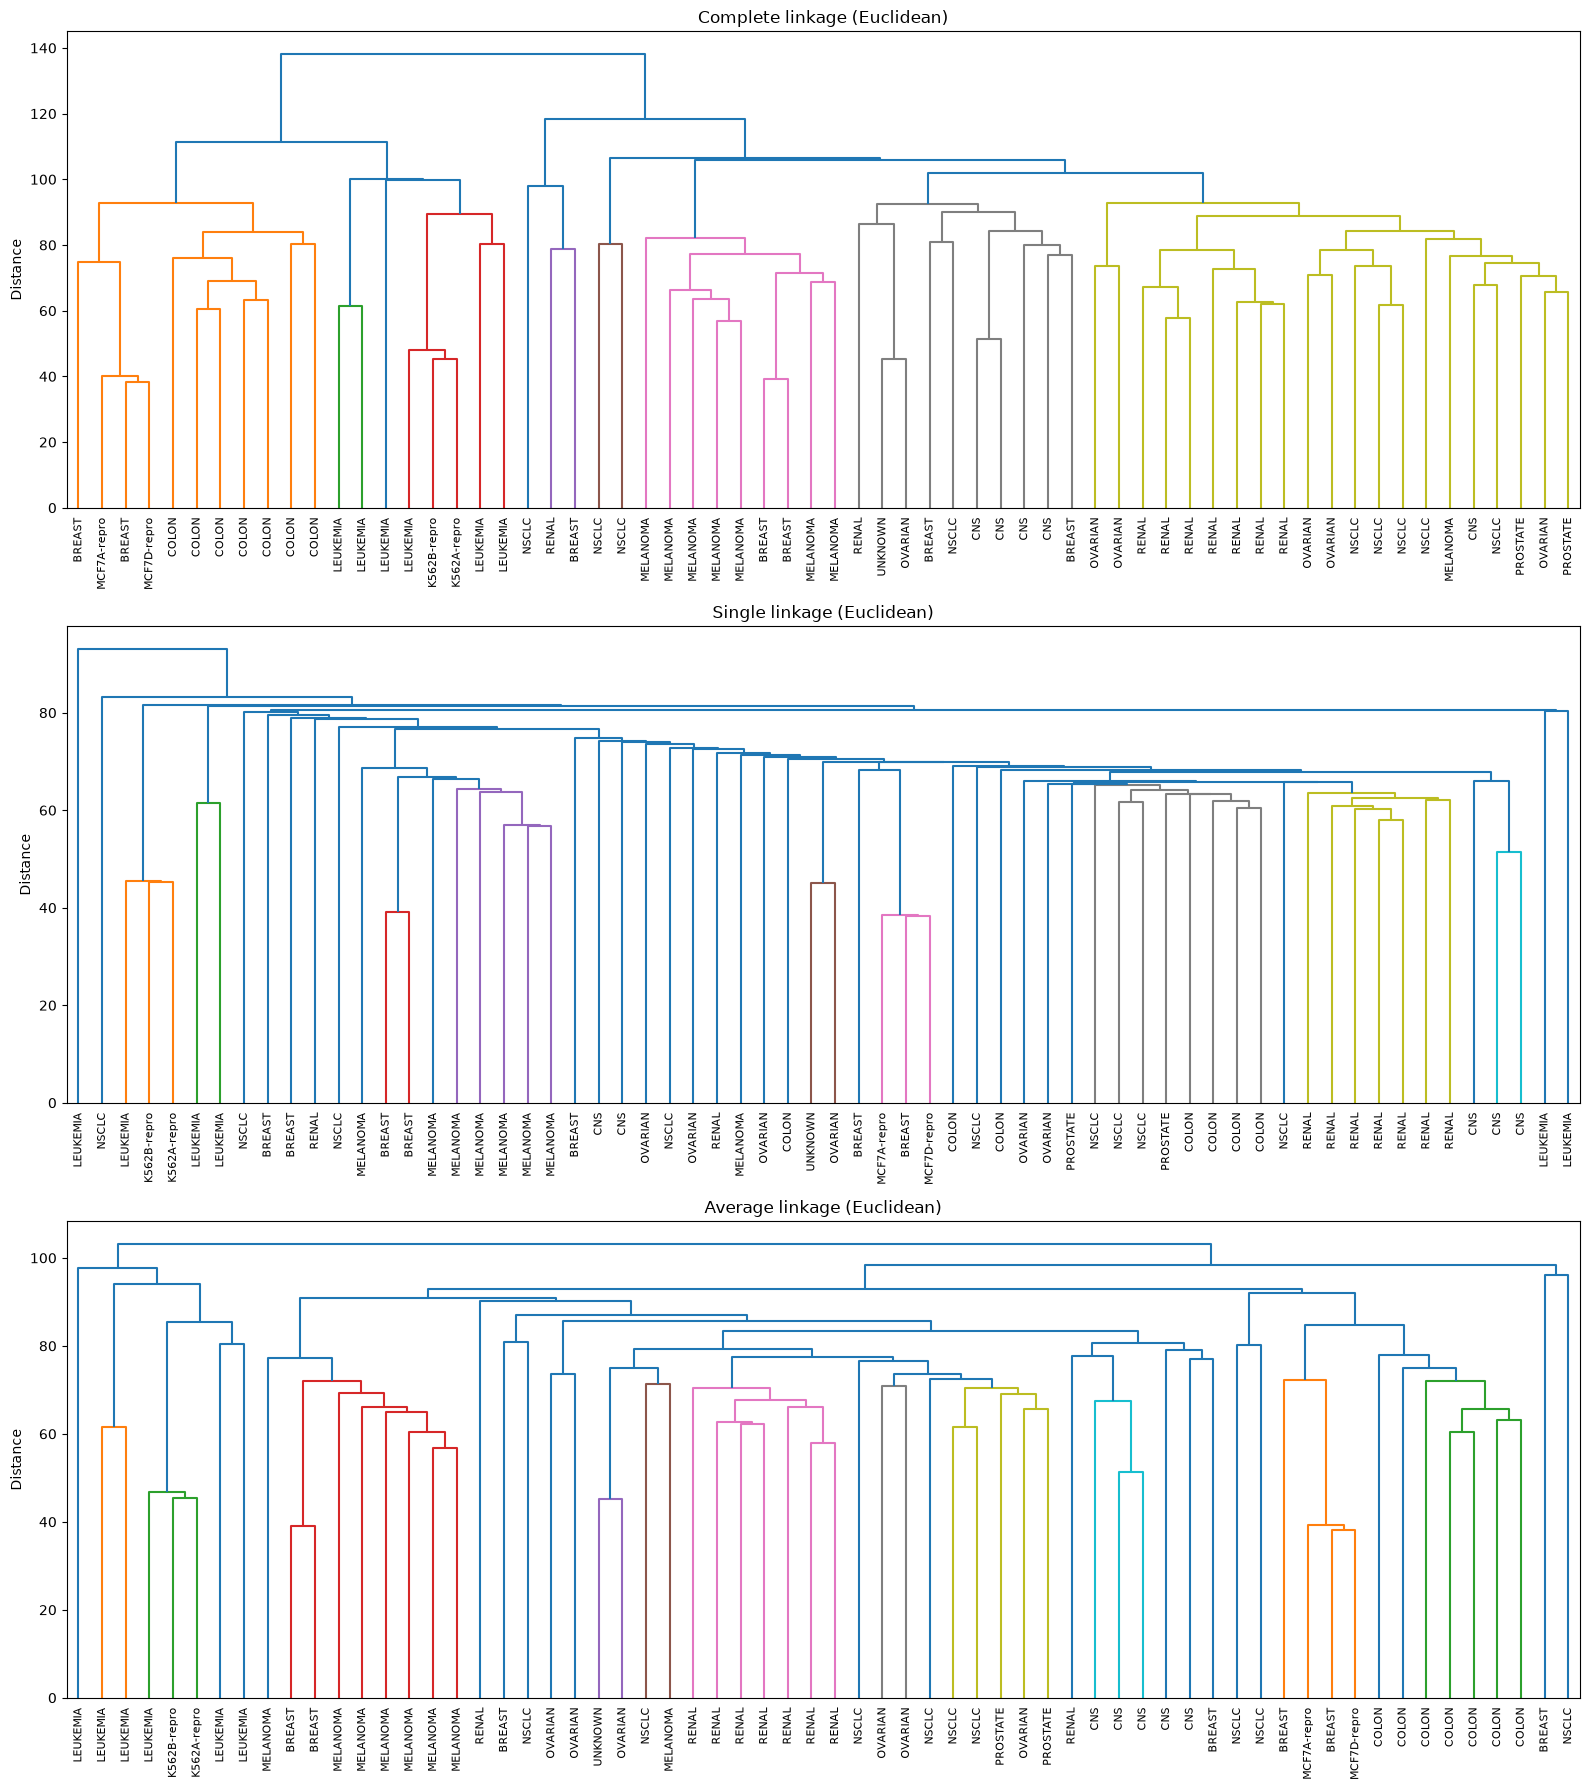

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Hierarchical clustering with 3 linkages + dendrograms
linkages = {}
fig, axes = plt.subplots(3, 1, figsize=(16, 18))
for ax, method in zip(axes, ["complete", "single", "average"]):
    linkages[method] = linkage(X, method=method, metric="euclidean")
    dendrogram(linkages[method], labels=y, leaf_rotation=90, leaf_font_size=8, ax=ax)
    ax.set_title(f"{method.capitalize()} linkage (Euclidean)")
    ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()



2. Complete linkage produced the most balanced dendrogram, with distinct branches that merge at large heights. Cutting it into four clusters gave sizes of 42, 11, 8, and 3. Single linkage produced a chaining structure, where samples are added to one growing cluster one at a time. Cutting it into four clusters gave sizes of 59, 3, 1, and 1, so almost all samples ended up in one cluster. Average linkage fell in between but was still unbalanced (54, 7, 2, 1). Complete linkage is the most useful of the three here because it is the only one that produces clusters of reasonable size.

3. Some cancer types separate clearly. All six leukemia samples cluster together, along with the K562 replicates, and all seven colon samples cluster together. Melanoma, renal, CNS, and ovarian samples also group mostly with their own type, but they sit inside one large cluster that also contains other types. Breast cancer is the most mixed type: its samples are spread across several clusters, and the MCF7 replicates landed with colon. Overall, the dendrograms recover some cancer types well, but not all of them, and the gene expression similarity between types is only partial.

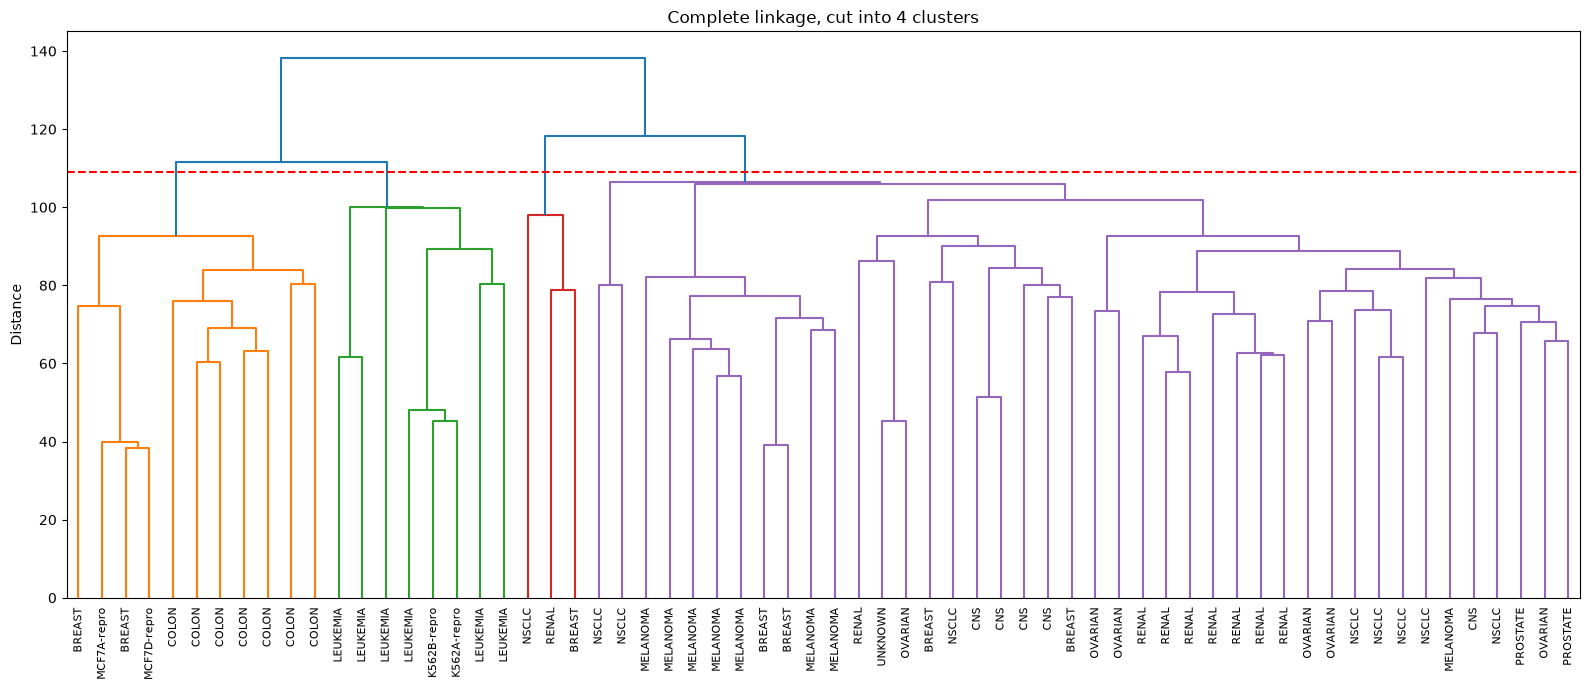

HC cluster   1  2  3  4
cancer type            
BREAST       2  0  1  4
CNS          0  0  0  5
COLON        7  0  0  0
K562A-repro  0  1  0  0
K562B-repro  0  1  0  0
LEUKEMIA     0  6  0  0
MCF7A-repro  1  0  0  0
MCF7D-repro  1  0  0  0
MELANOMA     0  0  0  8
NSCLC        0  0  1  8
OVARIAN      0  0  0  6
PROSTATE     0  0  0  2
RENAL        0  0  1  8
UNKNOWN      0  0  0  1


In [29]:
# 4 Complete linkage cut into 4 clusters
Z_c = linkages["complete"]
cut_height = (Z_c[-4, 2] + Z_c[-3, 2]) / 2   # midway between the 5→4 and 4→3 merges

plt.figure(figsize=(16, 7))
dendrogram(Z_c, labels=y, leaf_rotation=90, leaf_font_size=8, color_threshold=cut_height)
plt.axhline(cut_height, color="red", linestyle="--")
plt.title("Complete linkage, cut into 4 clusters")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

hc4 = fcluster(Z_c, t=4, criterion="maxclust")
print(pd.crosstab(y, hc4, rownames=["cancer type"], colnames=["HC cluster"]))


In [30]:
# internal validation scores for the 4-cluster partition
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

def internal_scores(data, labels):
    return {"Silhouette (higher=better)": silhouette_score(data, labels),
            "Calinski-Harabasz (higher=better)": calinski_harabasz_score(data, labels),
            "Davies-Bouldin (lower=better)": davies_bouldin_score(data, labels)}

scores_hc = internal_scores(X, hc4)
scores_hc


{'Silhouette (higher=better)': 0.07884960913370792,
 'Calinski-Harabasz (higher=better)': 5.010292812643681,
 'Davies-Bouldin (lower=better)': 2.1682612357608146}

4. With four clusters, one cluster contains the leukemia samples and K562 replicates, and one contains the colon samples plus a few breast and MCF7 samples. A small cluster has only three samples. The last cluster is large and mixes CNS, melanoma, NSCLC, ovarian, renal, and breast. The internal scores were weak: silhouette = 0.079, Calinski-Harabasz = 5.01, and Davies-Bouldin = 2.17. A silhouette close to zero means the clusters overlap and are not well separated. This is expected in a 6,830-dimensional space, where distances between samples become noisy.

In [31]:
# K-means with 4 clusters, compared with hierarchical
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters=4, n_init=20, random_state=0).fit(X)
km4 = km.labels_

print("ARI (KMeans vs complete-linkage HC):", adjusted_rand_score(hc4, km4))
print(pd.crosstab(hc4, km4, rownames=["HC cluster"], colnames=["KMeans cluster"]))
print("\nKMeans internal scores:", internal_scores(X, km4))


ARI (KMeans vs complete-linkage HC): 0.3046039208013063
KMeans cluster   0   1  2  3
HC cluster                  
1               11   0  0  0
2                0   0  8  0
3                0   3  0  0
4                9  24  0  9

KMeans internal scores: {'Silhouette (higher=better)': 0.11257991954605548, 'Calinski-Harabasz (higher=better)': 6.704726356743255, 'Davies-Bouldin (lower=better)': 2.2820088979622226}


5. The Adjusted Rand Index between K-Means (k = 4) and complete-linkage hierarchical clustering was 0.305, which shows only partial agreement. Both methods recover the leukemia group, but they disagree on how to split the large mixed group, which K-Means divides into three pieces. K-Means had slightly better internal scores (silhouette = 0.113, CH = 6.70), which is expected because it directly optimizes compact clusters.

Variance explained by 5 PCs: [0.149 0.083 0.066 0.043 0.038] total = 0.379


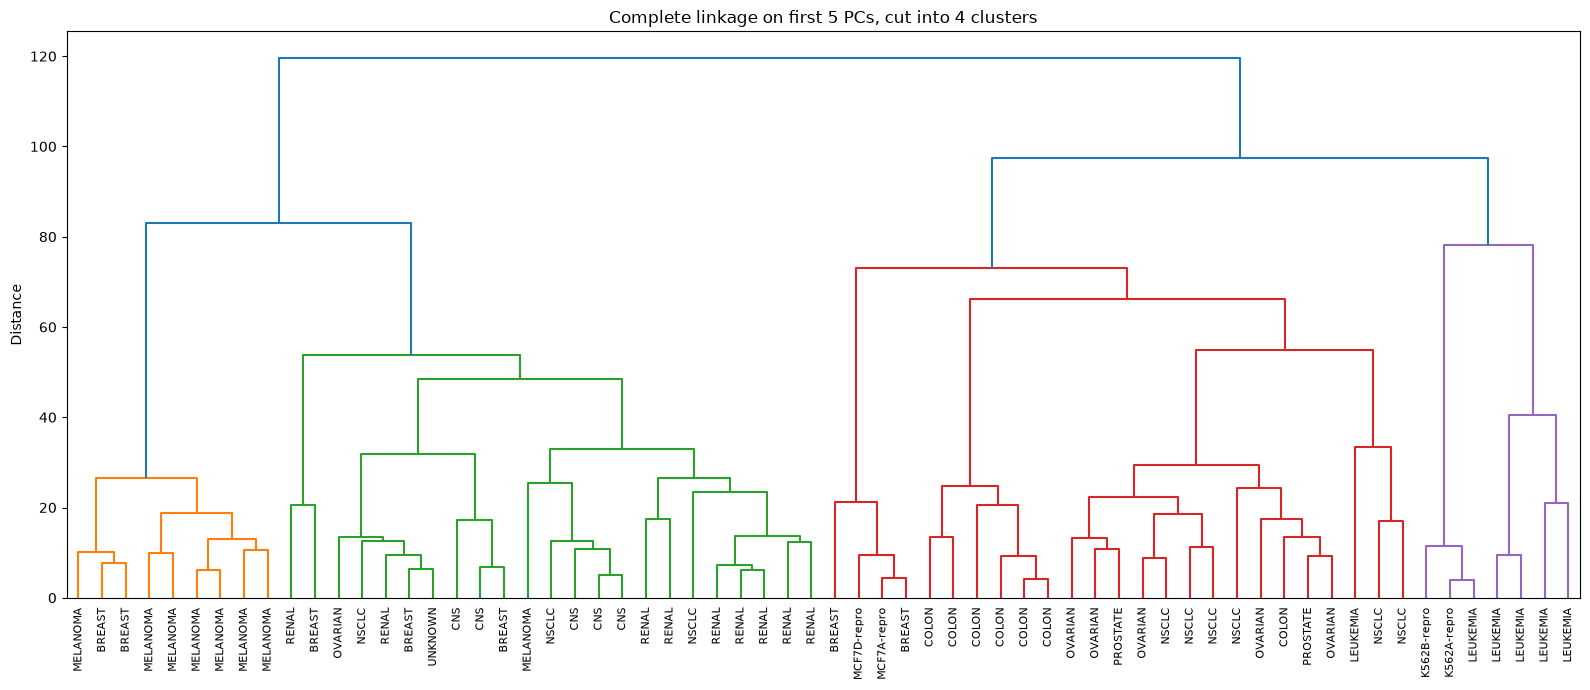

PCA-HC cluster  1  2  3  4
cancer type               
BREAST          2  3  2  0
CNS             0  5  0  0
COLON           0  0  7  0
K562A-repro     0  0  0  1
K562B-repro     0  0  0  1
LEUKEMIA        0  0  1  5
MCF7A-repro     0  0  1  0
MCF7D-repro     0  0  1  0
MELANOMA        7  1  0  0
NSCLC           0  3  6  0
OVARIAN         0  1  5  0
PROSTATE        0  0  2  0
RENAL           0  9  0  0
UNKNOWN         0  1  0  0


In [32]:
# PCA to 5 omponents, then hierarchical clustering
from sklearn.decomposition import PCA

pca = PCA(n_components=5)
X_pca = pca.fit_transform(X)
print("Variance explained by 5 PCs:", pca.explained_variance_ratio_.round(3),
      "total =", pca.explained_variance_ratio_.sum().round(3))

Z_p = linkage(X_pca, method="complete", metric="euclidean")
hc4_pca = fcluster(Z_p, t=4, criterion="maxclust")

plt.figure(figsize=(16, 7))
dendrogram(Z_p, labels=y, leaf_rotation=90, leaf_font_size=8,
           color_threshold=(Z_p[-4, 2] + Z_p[-3, 2]) / 2)
plt.title("Complete linkage on first 5 PCs, cut into 4 clusters")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

print(pd.crosstab(y, hc4_pca, rownames=["cancer type"], colnames=["PCA-HC cluster"]))


In [33]:
# internal and external metrics for the PCA based solution
comp = pd.DataFrame({
    "Original data HC (original space)": internal_scores(X, hc4),
    "PCA-5 HC (PCA space)": internal_scores(X_pca, hc4_pca),
    "PCA-5 HC labels (original space)": internal_scores(X, hc4_pca),
})
display(comp)

print("ARI (PCA-HC vs original HC):", adjusted_rand_score(hc4, hc4_pca))


,Original data HC (original space),PCA-5 HC (PCA space),PCA-5 HC labels (original space)
Silhouette (higher=better),0.078850,0.392057,0.113811
Calinski-Harabasz (higher=better),5.010293,34.681624,6.670487
Davies-Bouldin (lower=better),2.168261,0.955046,2.273164


ARI (PCA-HC vs original HC): 0.19606850671415002


7. The first five principal components explaTin only 37.9% of the variance. Clustering on them with complete linkage gave much better internal scores in the PCA space (silhouette = 0.392, CH = 34.68, Davies-Bouldin = 0.955), compared with 0.079, 5.01, and 2.17 for the original data. However, this comparison is not really fair, because the scores are measured in different spaces, and a 5-dimensional space with less noise produces higher scores. When we scored the PCA labels in the original space, the improvement was small (silhouette = 0.114, CH = 6.67, but Davies-Bouldin = 2.27, slightly worse). The ARI between the PCA-based and original partitions was 0.196, so the two solutions are quite different. The crosstab shows that renal and CNS samples now fall almost entirely in one cluster, and melanoma mostly in another. Overall, we think PCA modestly improved the clustering. It tightened the clusters and grouped some cancer types more cleanly, but the gains in the original space are small, and the low ARI shows that much of the original clustering was driven by noise in the full dataset.

## Part 3: Clustering gene expression between healthy and diseased groups (35 points)

The following dataset contains gene expression measurements for 40 tissue samples, each measured on 1,000 genes. The first 20 samples come from healthy patients, while the second 20 samples come from a diseased group.

1. Apply hierarchical clustering to the samples using a correlation-based distance. Use complete, average, and single linkage. Plot the resulting dendrogram for each case.

2. Looking at these dendrograms, which linkage criterion seems to provide better separation of the two groups?

3. Why do you think you were not asked to use Ward linkage here?

4. Now, focusing on complete linkage, cut the dendrogram into 2 clusters. Compare this clustering with the known group labels using the Adjusted Rand Index.

5. Use a two-sample t-test (e.g., the `ttest_ind` function from `scipy.stats`) to compute a p-value for each gene assessing its ability to discriminate between the two groups. There are 1000 genes, so apply a Bonferroni correction by using a significance threshold of α/1000 (with α = 0.05). In other words, consider a gene statistically significant if its p-value is less than 0.05/1000. Select all genes that meet this criterion.

6. Reapply hierarchical clustering to the samples, again with complete linkage and correlation-based distance, but now using only the significant genes. Cut the tree into 2 clusters and compute the Adjusted Rand Index with respect to the known labels. Which clustering solution shows better agreement with the true groups?

7. In the previous step, you should observe that clustering using only the significant genes leads to worse agreement with the known labels than using all 1000 genes, even though these genes were selected for their discriminative ability. Now repeat the hierarchical clustering using complete linkage and Euclidean distance on the significant genes. Cut the dendrogram into 2 clusters and compare the results with the known labels. Why does Euclidean distance produce a much better reconstruction than correlation distance in this scenario?

In [ ]:
import pandas as pd
import numpy as np

X = pd.read_csv("Lab08-part3_data.csv") # This is the dataset to use
# We know that the first 20 observations correspond to healthy patients, and the remaining 20 to disease. Let's create labels then:
y = np.array(["healthy"]*20 + ["disease"]*20)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## Part 4: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE